In [35]:
from utils import readin_raw, find_fds_for_rhs, fuzzy_filter,turnListToString, writeBackTrainingData, convertToDataFrame

In [36]:
import pandas as pd

In [37]:
data = pd.read_csv('../dataset.csv')

In [38]:
data

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False
...,...,...,...,...,...,...,...
563,546,points,firstseason,women_basketball.csv,False,True,False
564,547,points,lastseason,women_basketball.csv,False,True,False
565,548,birthDate,collegeOther,women_basketball.csv,False,True,False
566,549,birthDate,deathDate,women_basketball.csv,False,True,False


In [39]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

sentenceTransformer = SentenceTransformer("all-MiniLM-L6-v2")


In [40]:
texts = ["cat", "dog", "machine leaadwdlnawdrninawdasdg"]
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[0.9999999  0.6606375  0.16261387]
 [0.6606375  1.         0.20980448]
 [0.16261387 0.20980448 1.0000002 ]]


In [41]:
gen_data = data[data['is_genuine']]
nongen_data = data[data['is_genuine'] == False]

In [42]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [43]:
gen_similarites_unclean = gen_data.apply(build_cosine_sim, axis=1)

In [44]:
ungen_similarites_clean = nongen_data.apply(build_cosine_sim, axis=1)

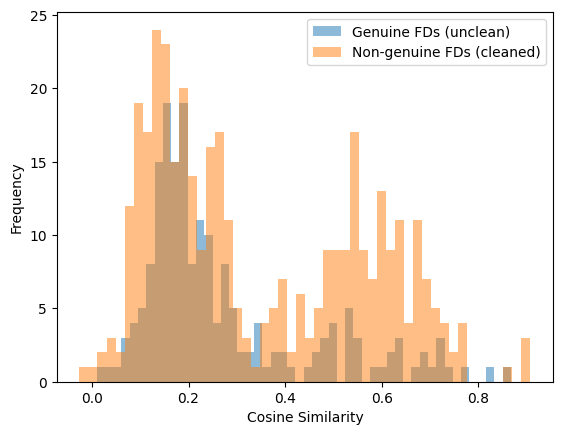

In [45]:
import matplotlib.pyplot as plt
plt.hist(gen_similarites_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_similarites_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [46]:
type(gen_similarites_unclean)

pandas.core.series.Series

In [47]:
texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.        , 0.17218277],
       [0.17218277, 1.        ]], dtype=float32)

In [48]:
import Levenshtein
print(Levenshtein.distance(texts[0], texts[1]))

12


In [49]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    lhs_ = ''
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance <= min_distance:
            min_distance = distance
            lhs_ = lhs_elem
    nominator = max(len(lhs_), len(rhs))
    return 1.0 - (float(min_distance) / float(nominator))

In [50]:
gen_leven_unclean = gen_data.apply(build_levenshtein, axis=1)
ungen_leven_clean = nongen_data.apply(build_levenshtein, axis=1)

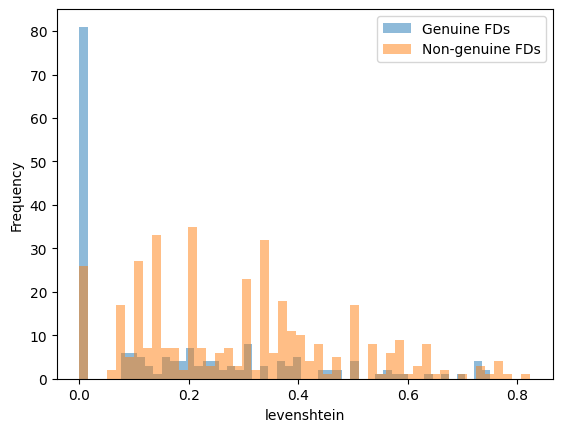

In [51]:
import matplotlib.pyplot as plt
plt.hist(gen_leven_unclean, bins=50, alpha=0.5, label='Genuine FDs')
plt.hist(ungen_leven_clean, bins=50, alpha=0.5, label='Non-genuine FDs')
plt.xlabel('levenshtein')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [52]:
def longest_common_substring(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp

    return a[best_end - best_len:best_end]



In [53]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    lhs_ = ''
    for lhs_elem in lhs:
        distance = len(longest_common_substring(lhs_elem, rhs))
        if distance >= max_distance:
            max_distance = distance
            lhs_ = lhs_elem
    
    nominator = float(min(len(lhs_), len(rhs)))
    return float(max_distance) / nominator

In [54]:
gen_lcs_unclean = gen_data.apply(build_lcs, axis=1)
ungen_lcs_clean = nongen_data.apply(build_lcs, axis=1)

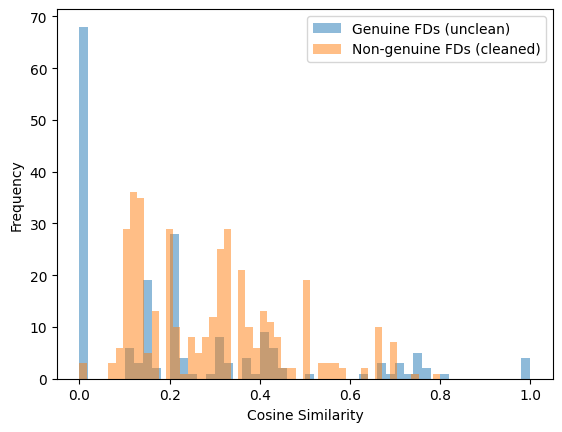

In [55]:
import matplotlib.pyplot as plt
plt.hist(gen_lcs_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_lcs_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [56]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.DataFrame()
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

X = df[["cosine_sim", "lcs", "leven"]]
y = df["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [57]:
df

,cosine_sim,lcs,leven,is_genuine
0,0.681850,0.750000,0.750000,True
1,0.640750,0.750000,0.400000,True
2,0.620726,0.750000,0.750000,True
3,0.503650,0.750000,0.400000,True
4,0.191531,0.375000,0.300000,True
...,...,...,...,...
563,0.236703,0.333333,0.181818,False
564,0.204837,0.333333,0.100000,False
565,0.144032,0.222222,0.166667,False
566,0.598772,0.666667,0.666667,False


In [58]:
clf = DecisionTreeClassifier(
    max_depth=5,        # prevents overfitting
    min_samples_leaf=5, # smoother splits
    random_state=42
)

clf.fit(X_train, y_train)


,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... note:: The search for a split does not stop until at least one valid partition of the node samples is found, even if it requires to effectively inspect more than ``max_features`` features.",None
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary ` for details.",42
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current no

In [59]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7894736842105263
              precision    recall  f1-score   support

       False       0.76      1.00      0.86        76
        True       1.00      0.37      0.54        38

    accuracy                           0.79       114
   macro avg       0.88      0.68      0.70       114
weighted avg       0.84      0.79      0.76       114



In [60]:
import pandas as pd

importance = pd.Series(
    clf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)


lcs           0.866929
cosine_sim    0.086305
leven         0.046766
dtype: float64


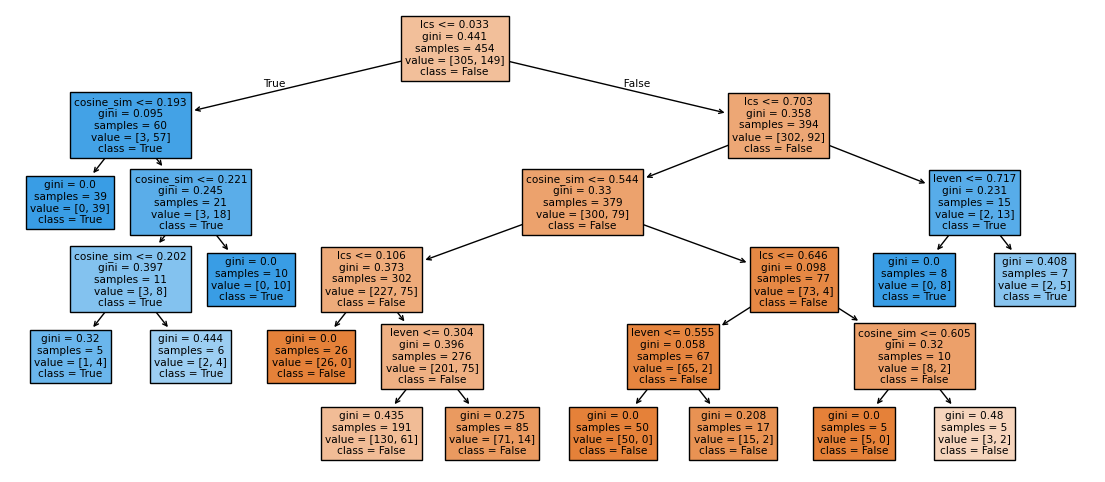

In [61]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["False", "True"],
    filled=True
)
plt.show()


In [62]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [63]:
clf = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",  # helpful if classes are imbalanced
    random_state=42
)

clf.fit(X_train_scaled, y_train)


,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",'balanced'
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:

In [64]:
y_pred = clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.6491228070175439
              precision    recall  f1-score   support

       False       0.78      0.66      0.71        76
        True       0.48      0.63      0.55        38

    accuracy                           0.65       114
   macro avg       0.63      0.64      0.63       114
weighted avg       0.68      0.65      0.66       114



In [65]:
y_pred

array([False, False,  True, False, False, False, False,  True,  True,
       False,  True,  True, False,  True, False, False, False,  True,
        True,  True, False,  True, False, False, False,  True, False,
        True, False,  True, False, False, False,  True,  True,  True,
       False,  True, False, False,  True, False, False, False, False,
       False,  True,  True, False,  True,  True,  True, False, False,
       False,  True,  True, False,  True, False,  True,  True,  True,
       False,  True,  True,  True,  True, False,  True,  True,  True,
       False,  True, False, False, False, False,  True, False, False,
        True,  True,  True,  True, False, False,  True, False,  True,
       False, False, False, False, False, False, False,  True, False,
        True, False,  True,  True, False, False,  True, False, False,
       False, False, False, False, False,  True])

In [66]:
import re

CAMEL_CASE_PATTERN = re.compile(
    r'''
    [A-Z]+(?=[A-Z][a-z]) |   # Acronyms followed by Capitalized words
    [A-Z]?[a-z]+ |           # Capitalized or lowercase words
    [A-Z]+ |                 # All-caps words
    \d+                      # Numbers
    ''',
    re.VERBOSE
)

def camel_case_tokenize(text: str) -> list[str]:
    return CAMEL_CASE_PATTERN.findall(text)


In [67]:
import numpy as np
levenshteins = np.array([], dtype=np.int16)
for t1 in texts:
    row = []
    for t2 in texts:
        row.append(Levenshtein)

## Building Features

### considering data type

In [68]:
# todo function: databasename + attributename -> SQL Type
#basketball team: "bioID","firstName","middleName","lastName","nameGiven","fullGivenName","marriedName","nameNick","pos","firstseason","lastseason","height","weight","college","collegeOther","birthDate","birthCity","birthState","birthCountry","highSchool","hsCity","hsState","hsCountry","deathDate","year","stint","tmID","lgID","GP","GS","minutes","points","oRebounds","dRebounds","rebounds","assists","steals","blocks","turnovers","PF","fgAttempted","fgMade","ftAttempted","ftMade","threeAttempted","threeMade","dq","PostGP","PostGS","PostMinutes","PostPoints","PostoRebounds","PostdRebounds","PostRebounds","PostAssists","PostSteals","PostBlocks","PostTurnovers","PostPF","PostfgAttempted","PostfgMade","PostftAttempted","PostftMade","PostthreeAttempted","PostthreeMade","PostDQ"
basektball_datatypes = {'bioID': 'varchar', 'firstName': 'varchar', 'middleName': 'varchar', 'lastName': 'varchar', 'nameGiven': 'varchar', 'fullGivenName': 'varchar', 'marriedName': 'varchar', 'nameNick': 'varchar', 'pos': 'varchar', 'firstseason':'int', 'lastseason':'int', 'height': 'float', 'weight':'int', 'college':'varchar', 'collegeOther':'varchar', 'birthDate':'date', 'birthCity':'varchar', 'birthState':'varchar', 'birthCountry':'varchar', 'highSchool':'varchar', 'hsCity':'varchar', 'hsState':'varchar', 'hsCountry':'varchar', 'deathDate':'date', 'year':'int', 'stint':'int', 'tmID':'varchar', 'lgID':'varchar', 'GP':'int', 'GS':'int', 'minutes':'int', 'points':'int', 'oRebounds':'int', 'dRebounds':'int', 'rebounds':'int', 'assists':'int', 'steals':'int', 'blocks':'int', 'turnovers':'int', 'PF':'int', 'fgAttempted':'int', 'fgMade':'int', 'ftAttempted':'int', 'ftMade':'int', 'threeAttempted':'int', 'threeMade':'int', 'dq':'int', 'PostGP':'int', 'PostGS':'int', 'PostMinutes':'int', 'PostPoints':'int', 'PostoRebounds':'int', 'PostdRebounds':'int', 'PostRebounds':'int', 'PostAssists':'int', 'PostSteals':'int', 'PostBlocks':'int', 'PostTurnovers':'int', 'PostPF':'int', 'PostfgAttempted':'int', 'PostfgMade':'int', 'PostftAttempted':'int', 'PostftMade':'int', 'PostthreeAttempted':'int', 'PostthreeMade':'int', 'PostDQ':'int'}
airline_datatypes ={ 'Year': 'int', 'Quarter':'int', 'Month':'int', 'DayofMonth':'int', 'DayOfWeek':'int', 'FlightDate':'date', 'UniqueCarrier':'varchar', 'AirlineID':'int', 'Carrier':'char', 'TailNum':'varchar', 'FlightNum':'int', 'OriginAirportID':'int', 'OriginAirportSeqID':'int', 'OriginCityMarketID':'int', 'Origin': 'char', 'OriginCityName': 'varchar', 'OriginState': 'char', 'OriginStateFips': 'int', 'OriginStateName': 'varchar', 'OriginWac': 'int', 'DestAirportID': 'int', 'DestAirportSeqID':'int', 'DestCityMarketID':'int', 'Dest':'char', 'DestCityName':'varchar', 'DestState':'char', 'DestStateFips':'int', 'DestStateName':'varchar', 'DestWac':'int', 'CRSDepTime':'int', 'DepTime':'int', 'DepDelay':'decimal', 'DepDelayMinutes':'float', 'DepDel15':'int', 'DepartureDelayGroups':'int', 'DepTimeBlk':'char', 'TaxiOut':'float', 'TaxiIn':'float', 'CRSArrTime':'int', 'ArrTime':'int', 'ArrDelay': 'decimal', 'ArrDelayMinutes': 'float', 'ArrDel15': 'int', 'ArrivalDelayGroups': 'ArrivalDelayGroups', 'ArrTimeBlk': 'char', 'Cancelled': 'int', 'CancellationCode': 'char', 'Diverted': 'int', 'CRSElapsedTime': 'float',  'ActualElapsedTime': 'float', 'AirTime': 'float', 'Flights': 'float', 'Distance':'float', 'DistanceGroup':'int', 'CarrierDelay': 'decimal', 'WeatherDelay':'decimal', 'NASDelay':'decimal', 'SecurityDelay':'decimal', 'LateAircraftDelay':'decimal', 'FirstDepTime':'decimal', 'TotalAddGTime':'decimal', 'LongestAddGTime':'decimal'}
mondial_datatypes = {"country_code": 'varchar',  "country_name":'varchar',  "country_capital_name":'varchar',  "country_capital_province":'varchar',  "country_area":'int',  "country_population":'int',  "city_position":'varchar',  "city_name":'varchar',  "city_country_code":'varchar',  "city_province":'varchar',  "city_population":'int',  "city_latitude":'double',  "city_longitude":'double',  "city_elevation":'int',  "airport_iata_code":'varchar',  "airport_name":'varchar',  "airport_country_code":'varchar',  "airport_city_name":'varchar',  "airport_province":'varchar',  "airport_island":'varchar',  "airport_latitude":'float',  "airport_longitude":'float',  "airport_elevation":'int',  "airport_gmt_offset":'int',  "language_name":'varchar',  "language_percentage":'double'  }
northwind_datatypes = {"OrderID":'int', "CustomerID":'varchar', "EmployeeID":'int', "ProductID":'int', "ord_OrderDate":'timestamp', "ord_RequiredDate":'timestamp', "ord_ShippedDate":'timestamp', "ord_ShipVia":'int', "ord_Freight":'double', "ord_ShipName":'varchar', "ord_ShipAddress":'varchar', "ord_ShipCity":'varchar', "ord_ShipRegion":'varchar', "ord_ShipPostalCode":'varchar', "ord_ShipCountry":'varchar', "cust_CompanyName":'varchar', "cust_ContactName":'varchar', "cust_ContactTitle":'varchar', "cust_Address":'varchar', "cust_City":'varchar', "cust_Region":'varchar', "cust_PostalCode":'varchar', "cust_Country":'varchar', "cust_Phone":'varchar', "cust_Fax":'varchar', "emp_LastName":'varchar', "emp_FirstName":'varchar', "emp_Title":'varchar', "emp_TitleOfCourtesy":'varchar', "emp_BirthDate":'timestamp', "emp_HireDate":'timestamp', "emp_Address":'varchar', "emp_City":'varchar', "emp_Region":'varchar', "emp_PostalCode":'varchar', "emp_Country":'varchar', "emp_HomePhone":'varchar', "emp_Extension":'int', "emp_ReportsTo":'int', "od_UnitPrice":'double', "od_Quantity": 'int', "od_Discount":'double', "prd_ProductName":'varchar', "prd_SupplierID":'int', "prd_CategoryID":'int', "prd_QuantityPerUnit":'varchar', "prd_UnitPrice":'double', "prd_UnitsInStock":'int', "prd_UnitsOnOrder":'int', "prd_ReorderLevel":'int', "prd_Discontinued":'bool',}
financial_datatypes = {"account_id": 'int', "account_date": 'date', "disp_id":'int', "disp_type":'varchar', "client_id":'int', "gender": 'varchar', "birth_date":'date', "district_id":'int', "A2":'varchar', "A3":'varchar', "A4":'int', "A5":'int', "A6":'int', "A7":'int', "A8":'int', "A9":'int', "A10":'decimal', "A11":'int', "A12":'decimal', "A13":'decimal', "A14":'int', "A15":'int', "A16":'int', "loan_id":'int', "loan_date":'date', "loan_amount":'int', "duration":'int', "payments":'decimal', "status": 'varchar', "order_id":'int', "bank_to":'varchar', "account_to":'int', "order_amount":'decimal', "k_symbol":'varchar'}

In [69]:
data['tablename'].unique()

array(['croppedairline.csv', 'mondialjoin.csv', 'northwind.csv',
       'financial.csv', 'women_basketball.csv'], dtype=object)

In [70]:
def datatype_for_row(lhs, rhs, dataset_name):
    datatypes = {}
    if dataset_name == 'croppedairline.csv':
        datatypes = airline_datatypes
    elif dataset_name == 'women_basketball.csv':
        datatypes = basektball_datatypes
    elif dataset_name == 'mondialjoin.csv':
        datatypes = mondial_datatypes
    elif dataset_name == 'northwind.csv':
        datatypes = northwind_datatypes
    elif dataset_name == 'financial.csv':
        datatypes = financial_datatypes
    else:
        return 'unknown', 'unknown'
    
    lhs_types = []
    for attr in lhs.split(','):
        attr = attr.strip()
        if attr in datatypes:
            lhs_types.append(datatypes[attr])
        else:
            lhs_types.append('unknown')
    
    rhs_type = datatypes.get(rhs, 'unknown')
    
    return ','.join(lhs_types), rhs_type

In [71]:
data_ft = data.copy() 
data_ft[['lhs_datatypes', 'rhs_datatype']] = data.apply(lambda row: datatype_for_row(row['lhs'], row['rhs'], row['tablename']), axis=1, result_type="expand")

In [72]:
data_ft.head()

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine,lhs_datatypes,rhs_datatype
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False,int,int
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False,int,int
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False,varchar,int
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False,float,int
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False,float,int


In [73]:
result = data_ft.groupby(['lhs_datatypes', 'rhs_datatype','is_genuine']).size().unstack(fill_value=0)

In [74]:
result.sort_values(by=False,axis=0, ascending=False)

,is_genuine,False,True
lhs_datatypes,rhs_datatype,,
varchar,varchar,86,31
int,int,41,66
varchar,int,35,4
float,int,20,2
int,varchar,15,43
...,...,...,...
"double,double",varchar,0,1
int,timestamp,0,4
varchar,float,0,1


In [75]:
def compute_posterior(true_fds, false_fds):
    prior_alpha = 0.5
    prior_beta = 0.5
    alpha_post = prior_alpha + true_fds
    beta_post = prior_beta + false_fds
    mean = alpha_post / (alpha_post + beta_post)
    var = (alpha_post * beta_post) / ((alpha_post + beta_post)**2 * (alpha_post + beta_post + 1))
    return mean,var

In [76]:
datatypes_dist = pd.DataFrame()
datatypes_dist[['mean', 'var' ]] = result.apply(lambda row: compute_posterior(row[True], row[False]), axis=1,result_type="expand")

In [77]:
datatypes_dist.sort_values(by='var', ascending=False)

,,mean,var
lhs_datatypes,rhs_datatype,,
ArrivalDelayGroups,int,0.250000,0.062500
"char,int",int,0.250000,0.062500
"char,date",int,0.250000,0.062500
"decimal,date",char,0.250000,0.062500
"decimal,decimal",varchar,0.250000,0.062500
...,...,...,...
int,varchar,0.737288,0.003228
varchar,int,0.112500,0.002435
int,int,0.615741,0.002171


(array([ 4.,  3.,  2.,  2.,  0.,  0.,  1.,  2.,  0.,  0.,  3.,  0.,  1.,
         0.,  0.,  0., 11.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0., 26.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 27.]),
 array([0.00164443, 0.00286154, 0.00407865, 0.00529577, 0.00651288,
        0.00772999, 0.0089471 , 0.01016421, 0.01138132, 0.01259843,
        0.01381554, 0.01503266, 0.01624977, 0.01746688, 0.01868399,
        0.0199011 , 0.02111821, 0.02233532, 0.02355244, 0.02476955,
        0.02598666, 0.02720377, 0.02842088, 0.02963799, 0.0308551 ,
        0.03207222, 0.03328933, 0.03450644, 0.03572355, 0.03694066,
        0.03815777, 0.03937488, 0.040592  , 0.04180911, 0.04302622,
        0.04424333, 0.04546044, 0.04667755, 0.04789466, 0.04911177,
        0.05032889, 0.051546  , 0.05276311, 0.05398022, 0.05519733,
        0.05641444, 0.05763155, 0.05884867, 0.06006578, 0.06128289,
        0.0625    ]),
 <BarContainer

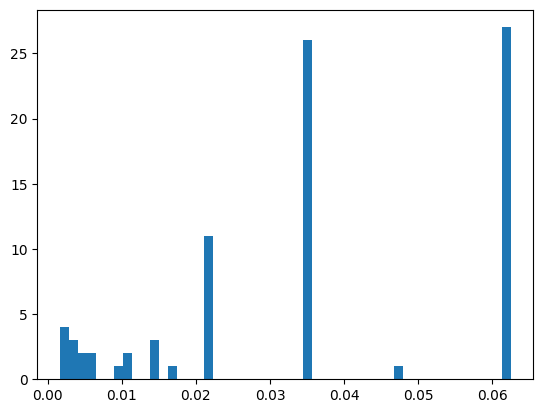

In [78]:
plt.hist(datatypes_dist['var'], bins=50, alpha=1, label='Variance of FD correctness by datatype pair')

In [79]:
datatypes_dist.sort_values(by='mean', ascending=False)

mean       var
lhs_datatypes   rhs_datatype                    
int             timestamp     0.900000  0.015000
char            varchar       0.833333  0.034722
                int           0.833333  0.034722
int             decimal       0.763158  0.009037
varchar,varchar double        0.750000  0.062500
...                                ...       ...
int,decimal     varchar       0.062500  0.006510
double,varchar  varchar       0.055556  0.005247
float           varchar       0.055556  0.005247
varchar         timestamp     0.045455  0.003616
timestamp       varchar       0.033333  0.002014

[83 rows x 2 columns]

In [80]:
def wrapper_lhs(entry):
    lhs = entry['lhs']
    rhs = entry['rhs']
    dataset_name = entry['tablename']
    lhs_types, _ = datatype_for_row(lhs, rhs, dataset_name)
    return lhs_types

def wrapper_rhs(entry):
    lhs = entry['lhs']
    rhs = entry['rhs']
    dataset_name = entry['tablename']
    _, rhs_type = datatype_for_row(lhs, rhs, dataset_name)
    return rhs_type

In [81]:

gen_lhs_type = gen_data.apply(wrapper_lhs, axis=1)
gen_rhs_type = gen_data.apply(wrapper_rhs, axis=1)

ungen_lhs_type = nongen_data.apply(wrapper_lhs, axis=1)
ungen_rhs_type = nongen_data.apply(wrapper_rhs, axis=1)

In [82]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.DataFrame()
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['data_type_lhs'] = pd.concat([gen_lhs_type, ungen_lhs_type], ignore_index=True)
df['data_type_rhs'] = pd.concat([gen_rhs_type, ungen_rhs_type], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

X = df[["cosine_sim", "lcs", "leven","data_type_lhs", "data_type_rhs"]]
y = df["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [83]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

num_cols = ["cosine_sim", "lcs", "leven"]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print(classification_report(y_test, pred))
ratio = len(pred[pred]) /len(pred)
print(f"pruning ratio in test data: {ratio}")


              precision    recall  f1-score   support

       False       0.93      0.86      0.89        76
        True       0.75      0.87      0.80        38

    accuracy                           0.86       114
   macro avg       0.84      0.86      0.85       114
weighted avg       0.87      0.86      0.86       114

pruning ratio in test data: 0.38596491228070173


In [84]:
proba = model.predict_proba(X_test)[:, 1]  # probability of True

threshold = 0.3
pred_adjusted_old = (proba >= threshold)
print(classification_report(y_test, pred_adjusted_old))

              precision    recall  f1-score   support

       False       0.93      0.84      0.88        76
        True       0.73      0.87      0.80        38

    accuracy                           0.85       114
   macro avg       0.83      0.86      0.84       114
weighted avg       0.86      0.85      0.85       114



In [85]:
ratio = len(pred[pred]) /len(pred)
print(f"pruning ratio in test data: {ratio}")

pruning ratio in test data: 0.38596491228070173


In [122]:
# seperator signs upperCase, hyphen, underscore
# has id, key, name, identifier
from itertools import product
import re

# global list for key indicators
keyAlike = ['id', 'key', 'name', 'identifier']
def upper_case_key(entry):
    lhs = entry['lhs']
    def split_by_uppercase(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        parts = re.split(r"(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])", s)
        return [p for p in parts if p]
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    split_has_key = False
    for attribute in attributes:
        up_split = split_by_uppercase( attribute )
        split_has_key = split_has_key or any(p[0].lower() == p[1].lower() for p in product(up_split, keyAlike))
    return split_has_key

def hyphen_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_hyphen(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("-") if p]
    
    split_has_hyphen = False
    for attribute in attributes:
        hy_split = split_by_hyphen( attribute )
        split_has_hyphen = split_has_hyphen or any(p[0].lower() == p[1].lower() for p in product(hy_split, keyAlike))
    return split_has_hyphen

def underscore_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_underscore(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("_") if p]
    
    split_has_underscore = False
    for attribute in attributes:
        un_split = split_by_underscore( attribute )
        split_has_underscore = split_has_underscore or any(p[0].lower() == p[1].lower() for p in product(un_split, keyAlike))
    return split_has_underscore

def contains_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    contains_any = any( key.lower() in attribute.lower() for attribute,key in product(attributes, keyAlike) )
    return contains_any


In [123]:
class FeatureBuilder: 
    def __init__(self):
        self.feature_functions = {}

    def add_feature(self, name, func):
        self.feature_functions[name] = func

    def build_dataset(self, data, exclude_table=None):
        df = pd.DataFrame()

        for name, func in self.feature_functions.items():
            df[name] = data.apply(func, axis=1)

        X = df[self.feature_functions.keys()]
        y = data["is_genuine"]
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y  # important for classification
        )
        return X_train, X_test, y_train, y_test
    def clear_features(self):
        self.feature_functions = {}

In [124]:
bob = FeatureBuilder()

In [125]:
bob.clear_features()
bob.add_feature('cosine_sim', build_cosine_sim)
bob.add_feature('lcs', build_lcs)
bob.add_feature('leven', build_levenshtein)
bob.add_feature('data_type_lhs', wrapper_lhs)
bob.add_feature('data_type_rhs', wrapper_rhs)
bob.add_feature('key_case', upper_case_key)
bob.add_feature('underscore_key', underscore_key)
bob.add_feature('contains_key', contains_key)
bob.add_feature('hyphen_key', hyphen_key)

In [126]:
X_train, X_test, y_train, y_test = bob.build_dataset(data)

In [127]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

num_cols_without = ["cosine_sim", "lcs", "leven" ]
num_cols_with = ["cosine_sim", "lcs", "leven", "key_case","underscore_key","contains_key" ]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess_without = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_without),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

preprocess_similarities = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_without),
    ]
)

preprocess_with = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_with),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

model_with= Pipeline(steps=[
    ("preprocess", preprocess_with),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model_without= Pipeline(steps=[
    ("preprocess", preprocess_without),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])
model_similarities=  Pipeline(steps=[
    ("preprocess", preprocess_similarities),
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

model_with.fit(X_train, y_train)
model_without.fit(X_train, y_train)
model_similarities.fit(X_train, y_train)
pedict_with = model_with.predict(X_test)
pedict_without = model_without.predict(X_test)
pedict_similarities = model_similarities.predict(X_test)

### Comparison keysubstring

In [128]:

print(classification_report(y_test, pedict_without))
ratio = len(pedict_without[pedict_without]) /len(pedict_without)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.93      0.83      0.88        77
        True       0.72      0.87      0.79        38

    accuracy                           0.84       115
   macro avg       0.82      0.85      0.83       115
weighted avg       0.86      0.84      0.85       115

pruning ratio in test data: 0.4


In [129]:

print(classification_report(y_test, pedict_with))
ratio = len(pedict_with[pedict_with]) /len(pedict_with)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.96      0.86      0.90        77
        True       0.76      0.92      0.83        38

    accuracy                           0.88       115
   macro avg       0.86      0.89      0.87       115
weighted avg       0.89      0.88      0.88       115

pruning ratio in test data: 0.4


In [130]:

print(classification_report(y_test, pedict_similarities))
ratio = len(pedict_similarities[pedict_similarities]) /len(pedict_similarities)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.76      0.61      0.68        77
        True       0.43      0.61      0.51        38

    accuracy                           0.61       115
   macro avg       0.60      0.61      0.59       115
weighted avg       0.65      0.61      0.62       115

pruning ratio in test data: 0.4608695652173913


In [131]:

print(classification_report(y_test, pedict_with))
ratio = len(pedict_with[pedict_with]) /len(pedict_with)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.96      0.86      0.90        77
        True       0.76      0.92      0.83        38

    accuracy                           0.88       115
   macro avg       0.86      0.89      0.87       115
weighted avg       0.89      0.88      0.88       115

pruning ratio in test data: 0.4


# log prop feature

In [141]:

lookup_df = pd.read_csv("../data/feature_logprops.csv")

data = data.merge(
    lookup_df,
    on=["tablename", "lhs", "rhs"],
    how="left"
)

MergeError: Passing 'suffixes' which cause duplicate columns {'improved_lb_log_x'} is not allowed.

In [138]:
data["has_log_bound"] = data["improved_lb_log"].notna().astype(int)


In [139]:
neutral_log_value = data.loc[
    data["has_log_bound"] == 1,
    "improved_lb_log"
].median()

data["improved_lb_log_filled"] = data["improved_lb_log"].fillna(neutral_log_value)

In [140]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

# -----------------------------
# 1) Build feature dataframe X
# -----------------------------
df = pd.DataFrame(index=data.index)

list_of_transformations = {
    "cosine_sim": build_cosine_sim,
    "lcs": build_lcs,
    "leven": build_levenshtein,
    "data_type_lhs": wrapper_lhs,
    "data_type_rhs": wrapper_rhs,
    "key_case": upper_case_key,
    "underscore_key": underscore_key,
    "contains_key": contains_key,
    "hyphen_key": hyphen_key,
}

for name, func in list_of_transformations.items():
    df[name] = data.apply(func, axis=1)

# Add your new probability-based features
df["improved_lb_log_filled"] = data["improved_lb_log_filled"]
df["has_log_bound"] = data["has_log_bound"]

X = df
y = data["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# -----------------------------
# 2) Preprocessing + model
# -----------------------------
num_cols = [
    "cosine_sim", "lcs", "leven",
    "key_case", "underscore_key", "contains_key", "hyphen_key",
    "improved_lb_log_filled", "has_log_bound",
]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess_final = ColumnTransformer(
    transformers=[
        ("num", Pipeline(steps=[
            ("scaler", StandardScaler())
        ]), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ],
    remainder="drop"
)

model_final = Pipeline(steps=[
    ("preprocess", preprocess_final),
    #("clf", LogisticRegression(max_iter=1000))
    # If imbalanced, consider:
    ("clf", LogisticRegression(max_iter=1000, class_weight="balanced"))
])

# -----------------------------
# 3) Train + evaluate
# -----------------------------
model_final.fit(X_train, y_train)
predict_final = model_final.predict(X_test)

print(classification_report(y_test, predict_final))


              precision    recall  f1-score   support

       False       0.93      0.87      0.90        82
        True       0.75      0.87      0.80        38

    accuracy                           0.87       120
   macro avg       0.84      0.87      0.85       120
weighted avg       0.88      0.87      0.87       120



### adjusted threshold

In [ ]:
proba = model_final.predict_proba(X_test)[:, 1]  # probability of True

thresholds = np.arange(0,1.1,0.1)
ratios = []
recalls = []
for t in thresholds:
    pred_adjusted = (proba >= t)
    recalls+= [ classification_report(y_test, pred_adjusted,output_dict=True)['True']["recall"]]
    ratio = 1 - (len(pred_adjusted[pred_adjusted]) / len(pred_adjusted))
    ratios += [ratio]


/home/jannis/University/dataprofiling/dataprofiling_gen_fd/datagen/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jannis/University/dataprofiling/dataprofiling_gen_fd/datagen/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/jannis/University/dataprofiling/dataprofiling_gen_fd/datagen/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1833: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Us

In [ ]:
ratios

[0.0,
 0.35652173913043483,
 0.4,
 0.4434782608695652,
 0.5478260869565217,
 0.6,
 0.6260869565217391,
 0.6521739130434783,
 0.6956521739130435,
 0.8434782608695652,
 1.0]

In [ ]:
recalls

[1.0,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9736842105263158,
 0.9473684210526315,
 0.9210526315789473,
 0.868421052631579,
 0.7894736842105263,
 0.3684210526315789,
 0.0]

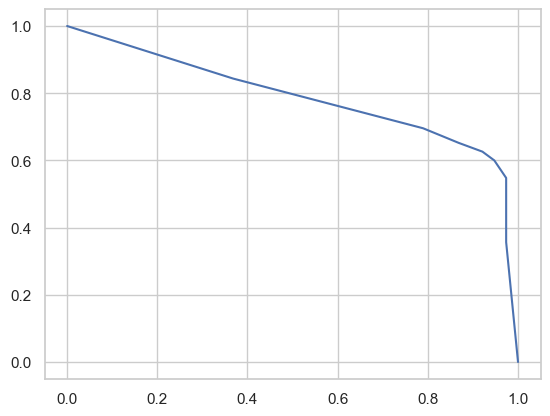

In [136]:
plt.plot(recalls, ratios)

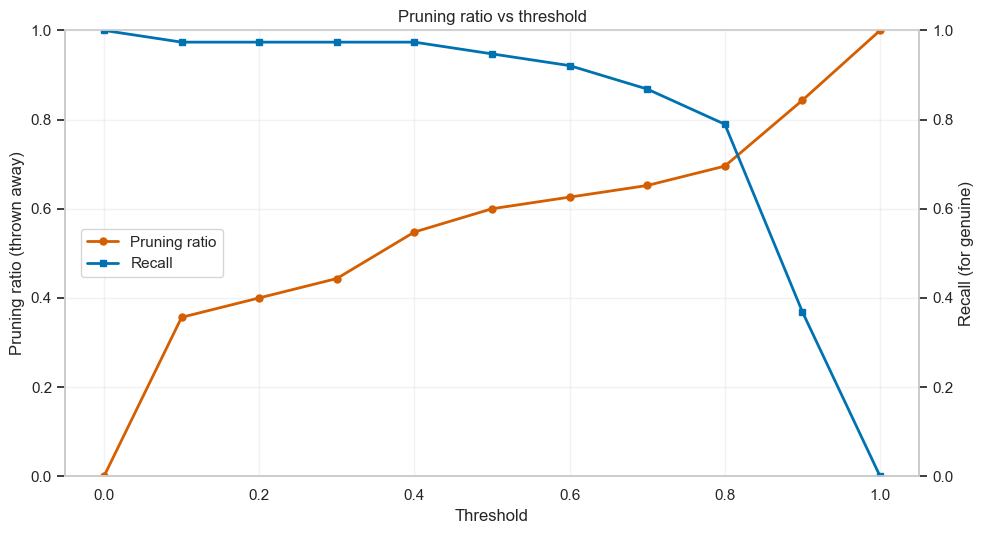

In [121]:
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

# Inputs (you already have these)
# ratio  = fraction of ALL samples thrown away (pred=False) at each threshold
# recall = recall of True class (kept among true) at each threshold

def plot_pruning_tradeoff_ratio_recall(ratio, recall, title="Pruning ratio vs threshold"):
    ratio = np.asarray(ratio, dtype=float)
    recall = np.asarray(recall, dtype=float)

    if ratio.shape != recall.shape:
        raise ValueError(f"`ratio` and `recall` must have the same length. Got {len(ratio)} vs {len(recall)}")

    # If you don't already have thresholds, assume they're evenly spaced [0, 1]
    thresholds = np.linspace(0, 1, len(ratio))

    sns.set_theme(style="whitegrid", context="notebook")
    fig, ax1 = plt.subplots(figsize=(10, 5.5))

    # Color coding
    color_throw = "#d55e00"   # orange/red
    color_recall = "#0072b2"  # blue

    # Left axis: thrown away ratio
    line_throw, = ax1.plot(
        thresholds, ratio,
        color=color_throw, marker="o", markersize=5, linewidth=2,
        label="Pruning ratio"
    )
    ax1.set_xlabel("Threshold")
    ax1.set_ylabel("Pruning ratio (thrown away)")
    ax1.set_ylim(0, 1)
    ax1.grid(True, alpha=0.25)

    # Right axis: recall
    ax2 = ax1.twinx()
    line_recall, = ax2.plot(
        thresholds, recall,
        color=color_recall, marker="s", markersize=5, linewidth=2,
        label="Recall"
    )
    ax2.set_ylabel("Recall (for genuine)")
    ax2.set_ylim(0, 1)
    ax2.grid(False)

    # Single legend: vertically centered on the left
    ax1.legend(
        [line_throw, line_recall],
        [line_throw.get_label(), line_recall.get_label()],
        loc="center left",
        bbox_to_anchor=(0.01, 0.5),
        frameon=True
    )

    ax1.set_title(title)
    sns.despine(ax=ax1, right=False)
    plt.tight_layout()
    plt.show()

# Call it:
plot_pruning_tradeoff_ratio_recall(ratios, recalls)


In [132]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# predicted probabilities for the positive class
y_score = model_final.predict_proba(X_test)[:, 1]

# ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_score)

# AUC
auc = roc_auc_score(y_test, y_score)



ValueError: columns are missing: {'improved_lb_log_filled', 'has_log_bound'}